<a href="https://colab.research.google.com/github/matbarrett/LinAlgProject/blob/main/notebooks/04_which_images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 4

In [20]:
from pathlib import Path
import subprocess
import sys

# Use this checkout locally, or download the project when running in Colab.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "bird_image.jpg").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    ROOT = Path.cwd() / "LinAlgProject"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "https://github.com/matbarrett/LinAlgProject.git",
                        str(ROOT)], check=True)
sys.path.insert(0, str(ROOT / "src"))
print("Project:", ROOT.name)

Project: LinAlgProject


In [21]:
from compress import rank_k_approx, rel_error, predicted_error, compression_ratio
import numpy as np
import matplotlib.pyplot as plt
def k_for_error(s, target):
  """Smallest k whose relative error is at most target."""
  for k in range(1, len(s) + 1):
    if predicted_error(s, k) <= target:
      return k

In [22]:
N = 256
i, j = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
def stripes(angle, width=16):
  """Black and white stripes, tilted by `angle` degrees."""
  t = np.deg2rad(angle)
  return 255.0 * (np.floor((i * np.cos(t) + j * np.sin(t)) / width) % 2)
rng = np.random.default_rng(0)
patterns = {
  "stripes, 0 deg": stripes(0),
  "stripes, 45 deg": stripes(45),
  "checkerboard": 255.0 * ((i // 32 + j // 32) % 2),
  "disk": 255.0 * ((i - N/2)**2 + (j - N/2)**2 < (N/3)**2),
  "noise": rng.integers(0, 256, size=(N, N)).astype(float),
}

In [23]:
for name, P in patterns.items():
  s = np.linalg.svd(P, compute_uv=False)
  k5 = k_for_error(s, 0.05)
  print(f"{name:16s} rank = {np.linalg.matrix_rank(P):3d} k for 5% = {k5:3d}"
  f" ratio = {compression_ratio(N, N, k5):6.2f}")

stripes, 0 deg   rank =   1 k for 5% =   1 ratio = 127.75
stripes, 45 deg  rank = 182 k for 5% =  64 ratio =   2.00
checkerboard     rank =   2 k for 5% =   2 ratio =  63.88
disk             rank =  51 k for 5% =  26 ratio =   4.91
noise            rank = 256 k for 5% = 198 ratio =   0.65


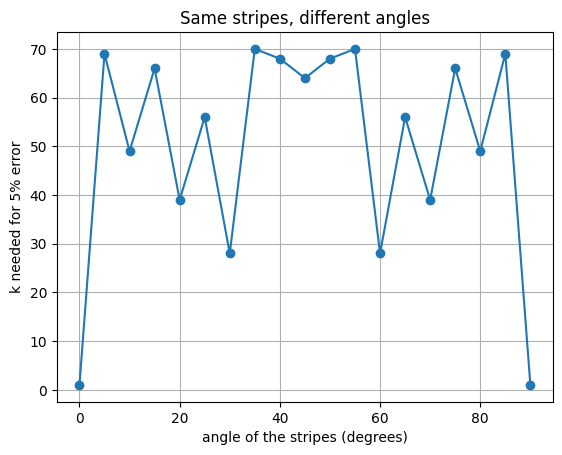

In [24]:
angles = np.arange(0, 91, 5)
ks = [k_for_error(np.linalg.svd(stripes(a), compute_uv=False), 0.05) for a in angles]
plt.plot(angles, ks, "o-")
plt.xlabel("angle of the stripes (degrees)")
plt.ylabel("k needed for 5% error")
plt.title("Same stripes, different angles")
plt.grid()
plt.savefig("angles.png", dpi=150)
plt.show()